# Miniprojekt B

## Frekvensanalyse af EKG, EMG og Blodtryk

**Navne:** Jakob og Lucas 

**AU-ID:**  fdfsdf 


### Indhold:
1. sampletid og tidsplot af muskelsignalerne
2. Frekvenstransformation af 630 signaler
3. Energi under og over 200 Hz
4. Zero-padding til ottedobbeltlængde 
5. R-takker, puls og Heart Rate Variability
6. STFT og frekvensindhold i hvert QRS-kompleks
7. Tre blodtrykssignaler med og uden spektral udglatning
8. Bogopgaver og samlet konklusion


ja troede i starten at vi skulle lave en funktion som hed analysatoren som har blot lige gemt den her men nåede ikke i mål synes det lød dumt 

In [1]:
def frekvensanalyse(x, fsample, N=None):
    """
    Beregner et ensidet amplitude- og energispektrum.

    x       : målt signal
    fsample : samplefrekvens i Hz
    N       : FFT-længde. N >= len(x)
    """
    x = np.asarray(x, dtype=float).ravel()
    L = len(x)
    
    # DFT beregnet med FFT-algoritmen
    X = np.fft.rfft(x, n=N)
    f = np.fft.rfftfreq(N, d=1 / fsample)

    # Ensidet amplitudespektrum
    amplitude = np.abs(X) / L

    # Energi pr. frekvens-bin ifølge Parsevals sætning
    Ebin = np.abs(X)**2 / N

    if N % 2 == 0:
        # Fordobl alle punkter undtagen DC og Nyquist
        amplitude[1:-1] *= 2
        Ebin[1:-1] *= 2
    else:
        # Ved ulige N findes intet Nyquist-punkt
        amplitude[1:] *= 2
        Ebin[1:] *= 2

    return {
        "f": f,
        "X": X,
        "amplitude": amplitude,
        "Ebin": Ebin,
        "E_time": np.sum(x**2),
        "E_frequency": np.sum(Ebin),
        "df": fsample / N,
        "L": L,
        "N": N
    }

## 1. sampletid og tidsplot af muskelsignalerne

"Importer de to muskelsignaler fra Brightspace ‘EMG_Healthy’ og
‘EMG_Myopathy’. Bestem sampletiden og dernæst samplefrekvensen - og plot
så de første 630 samples af begge signaler. Beskriv ligheder og forskelle"

0.00025 0.0005 0.00025
EMG-målepunkter pr signal: Healthy: 630 Myopathy: 630
Healthy:  Sampletiden (Ts) = 0.000250 s
Myopathy: Sampletiden (Ts) = 0.000250 s
Healthy: Samplefrekvens (fs) = 4000 Hz
Myopathy: Samplefrekvens (fs) = 4000 Hz


Text(0, 0.5, 'Amplitude')

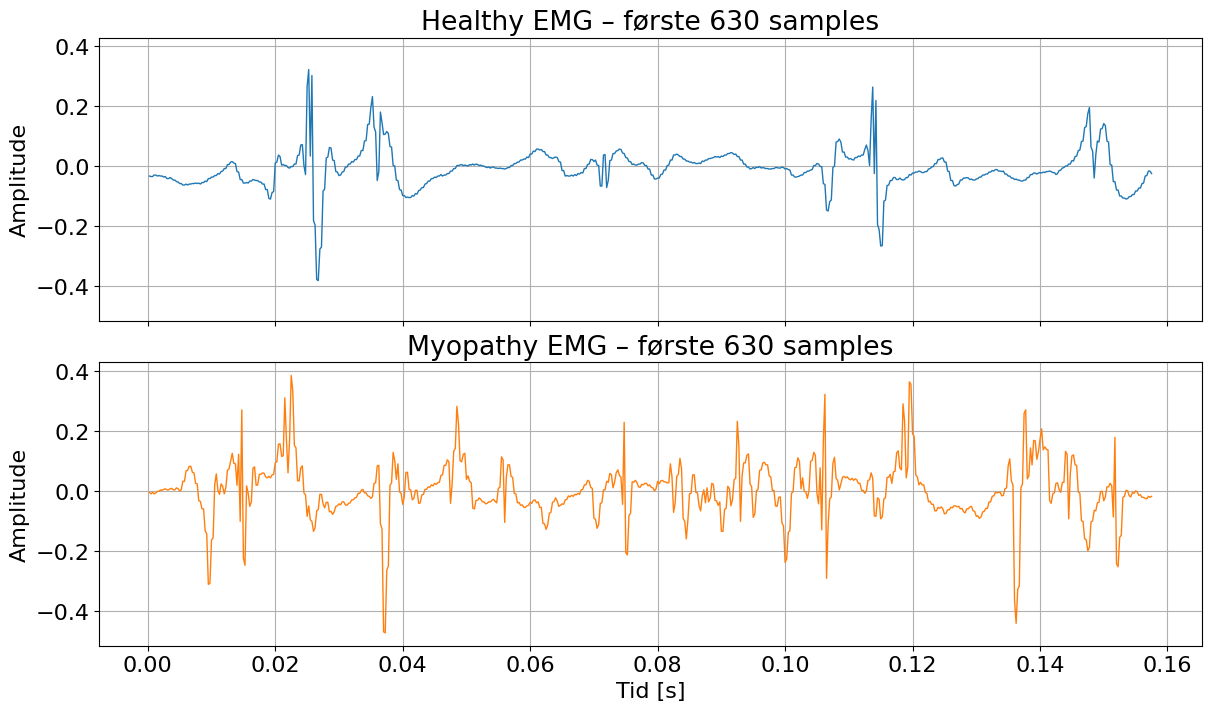

In [ ]:
import numpy as np
from scipy import signal
from scipy.io import loadmat
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["font.size"] = 16
plt.rcParams["axes.grid"] = True

healthy = np.loadtxt("EMG_Healthy.txt", max_rows=630)
myopathy = np.loadtxt("EMG_Myopathy.txt", max_rows=630)

# Kolonne 0 = tid, kolonne 1 = EMG signal
t_healthy = healthy[:, 0]
x_healthy = healthy[:, 1]

t_myopathy = myopathy[:, 0]
x_myopathy = myopathy[:, 1]

#målinger pr sekund
dt_healthy = t_healthy[1] - t_healthy[0]
dt_myopathy = t_myopathy[1] - t_myopathy[0]

# Sample frekvens
fs_healthy = 1 / dt_healthy
fs_myopathy = 1 / dt_myopathy

print("EMG-målepunkter pr signal:", "Healthy:", len(x_healthy), "Myopathy:", len(x_myopathy))
print(f"Healthy:  Sampletiden (Ts) = {dt_healthy:.6f} s")
print(f"Myopathy: Sampletiden (Ts) = {dt_myopathy:.6f} s")
print(f"Healthy: Samplefrekvens (fs) = {fs_healthy:.0f} Hz")
print(f"Myopathy: Samplefrekvens (fs) = {fs_myopathy:.0f} Hz")

emg = {"healthy": {
    "t": t_healthy,
    "x": x_healthy,
    "dt": dt_healthy,
    "fs": fs_healthy
}
, "myopathy": {
    "t": t_myopathy,
    "x": x_myopathy,
    "dt": dt_myopathy,
    "fs": fs_myopathy
}
}

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True)

ax[0].plot(t_healthy, x_healthy, linewidth=1)
ax[0].set_title("Healthy EMG – første 630 samples")
ax[0].set_ylabel("Amplitude")

ax[1].plot(t_myopathy, x_myopathy, linewidth=1, color="tab:orange")
ax[1].set_title("Myopathy EMG – første 630 samples")
ax[1].set_xlabel("Tid [s]")
ax[1].set_ylabel("Amplitude")

Sampletiden findes som forskellen mellem to på hinanden følgende
tidspunkter:

Sampletiden beregnes som:

$$
T_s = t_1 - t_0 = 0{,}00025\,\mathrm{s}
$$

Samplefrekvensen bliver derfor:

$$
f_s = \frac{1}{T_s}
= \frac{1}{0{,}00025\,\mathrm{s}}
= 4000\,\mathrm{Hz}
$$

Begge EMG-signaler har dermed samme sampletid og samplefrekvens.
Begge signaler svinger omkring nul og indeholder både positive og
negative, ikke-periodiske udsving.

I de første 630 samples fremstår signalet fra personen med myopati
mere uroligt og indeholder flere hyppige og skarpe udsving. Det raske
signal har generelt længere rolige områder, som afbrydes af enkelte
tydelige aktivitetsudbrud.

## 2. Frekvenstransformation af 630 signaler

"Lav frekvenstransformation på de første 630 samples af signalerne i 1), benyt
N=2000 og vis frekvensspektrene. Beskriv igen ligheder og forskelle"

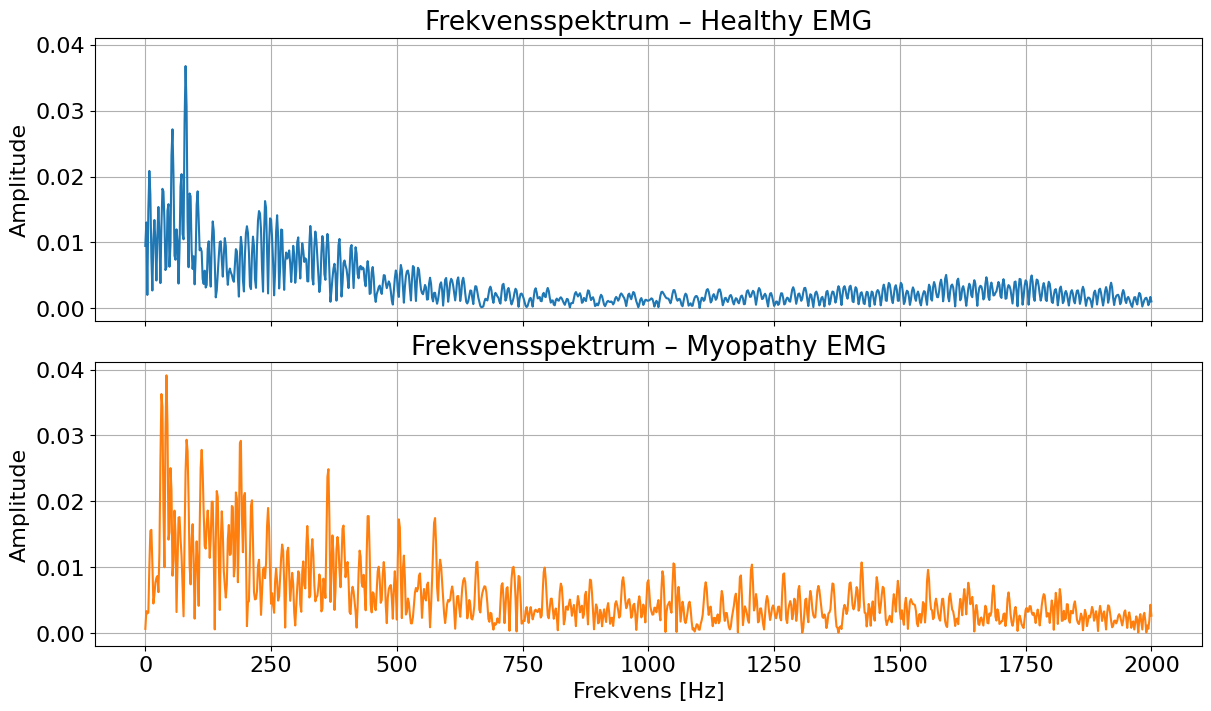

In [ ]:
# FFT-længde
N = 2000
L = 630

def amplitudespektrum(x, fs, N):
    x = np.asarray(x)
    L = len(x)

    # FFT med zero-padding fra 630 til 2000 punkter
    X = np.fft.rfft(x, n=N)

    # Frekvensakse fra 0 til Nyquistfrekvensen
    f = np.fft.rfftfreq(N, d=1/fs)

    # Ensidet amplitudespektrum
    A = np.abs(X) / L
    A[1:-1] *= 2

    return f, A

f_healthy, A_healthy = amplitudespektrum(emg["healthy"]["x"], emg["healthy"]["fs"], N)
f_myopathy, A_myopathy = amplitudespektrum(emg["myopathy"]["x"], emg["myopathy"]["fs"], N)

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

ax[0].plot(f_healthy, A_healthy)
ax[0].set_title("Frekvensspektrum – Healthy EMG")
ax[0].set_ylabel("Amplitude")

ax[1].plot(f_myopathy, A_myopathy, color="tab:orange")
ax[1].set_title("Frekvensspektrum – Myopathy EMG")
ax[1].set_xlabel("Frekvens [Hz]")
ax[1].set_ylabel("Amplitude")

plt.show()

FFT-længde på \(N=2000\). Signalerne er blevet
zero-paddet med 1370 nuller. Frekvensafstanden i det viste spektrum er:

$$
\Delta f = \frac{f_s}{N}
= \frac{4000}{2000}
= 2\,\mathrm{Hz}
$$

begge signaler har hobedsageligt deres største amplituder ved de lavere frekvenser. 

Den største spektrale amplitude findes omkring 80-100 Hz for det raske signal og omkring 40-50 Hz for myopati-signalet. Myopati-signalet har flere fremtrædende toppe fordelt over frekvensaksen, hvilket viser, at dets variationer er fordelt over et bredere frekvensområde. Dette hænger sammen med de hyppigere og skarpere udsving, som ses ovenover i tidsdomænet.

### 3. Energi under og over 200 Hz

"Bestem lavfrekvent energi (under 200Hz) og højfrekvent energi (over 200Hz) for
de to signaler og sammenlign det sunde muskelsignal med det for muskelsvind"

Brug samme segment på 630 samples og samme FFT-længde N=2000. Energien beregnes med Parsevals sætning:
$$
E=\sum_n |x[n]|^2
=\frac{1}{N}\sum_k |X[k]|^2
$$
Her placeres frekvenspunktet præcis ved 200 Hz i det lavfrekvente område:

In [8]:
def beregn_energiområder(x, fs, N=2000, grænse=200):
    x = np.asarray(x)
    
    # DFT med zero-padding
    X = np.fft.rfft(x, n=N)
    f = np.fft.rfftfreq(N, d=1/fs)

    # Energi pr. frekvens-bin
    Ebin = np.abs(X)**2 / N

    # Fordobling ved ensidet spektrum,
    # undtagen DC og Nyquist
    if N % 2 == 0:
        Ebin[1:-1] *= 2
    else:
        Ebin[1:] *= 2

    # 200 Hz medtages i det lavfrekvente område
    E_lav = np.sum(Ebin[f <= grænse])
    E_høj = np.sum(Ebin[f > grænse])
    E_total = E_lav + E_høj

    return {
        "lav": E_lav,
        "høj": E_høj,
        "total": E_total,
        "lav_procent": 100 * E_lav / E_total,
        "høj_procent": 100 * E_høj / E_total
    }


energi_healthy = beregn_energiområder(
    x_healthy, fs_healthy
)

energi_myopathy = beregn_energiområder(
    x_myopathy, fs_myopathy
)

for navn, energi in [
    ("Healthy", energi_healthy),
    ("Myopathy", energi_myopathy)
]:
    print(navn)
    print(f"  Lavfrekvent energi: {energi['lav']:.4f}")
    print(f"  Højfrekvent energi: {energi['høj']:.4f}")
    print(f"  Lavfrekvent andel:  {energi['lav_procent']:.2f} %")
    print(f"  Højfrekvent andel:  {energi['høj_procent']:.2f} %")
    print(f"  Total energi:       {energi['total']:.4f}")

Healthy
  Lavfrekvent energi: 1.4414
  Højfrekvent energi: 1.2251
  Lavfrekvent andel:  54.06 %
  Højfrekvent andel:  45.94 %
  Total energi:       2.6666
Myopathy
  Lavfrekvent energi: 2.8801
  Højfrekvent energi: 2.9435
  Lavfrekvent andel:  49.46 %
  Højfrekvent andel:  50.54 %
  Total energi:       5.8236


Myopati-signalet har mere absolut energi i begge
frekvensområder. Den lavfrekvente energi er cirka dobbelt så stor,
mens den højfrekvente energi er cirka 2.5 gange så stor som for
det raske signal. Det raske signal har størstedelen af sin energi
under 200 Hz, mens myopati-signalets energi er næsten ligeligt
fordelt, med en lidt større andel over 200 Hz.

### 4. Zero-padding til ottedobbeltlængde 

"Zero-pad ‘EMG_Healthy’ til ottedobbelt længde. Lav igen frekvenstransformation
(nu med N=16000) og sammenlign med det tilsvarende spektrum fra 2"

N = 2000:  Δf = 2.00 Hz
N = 16000: Δf = 0.25 Hz


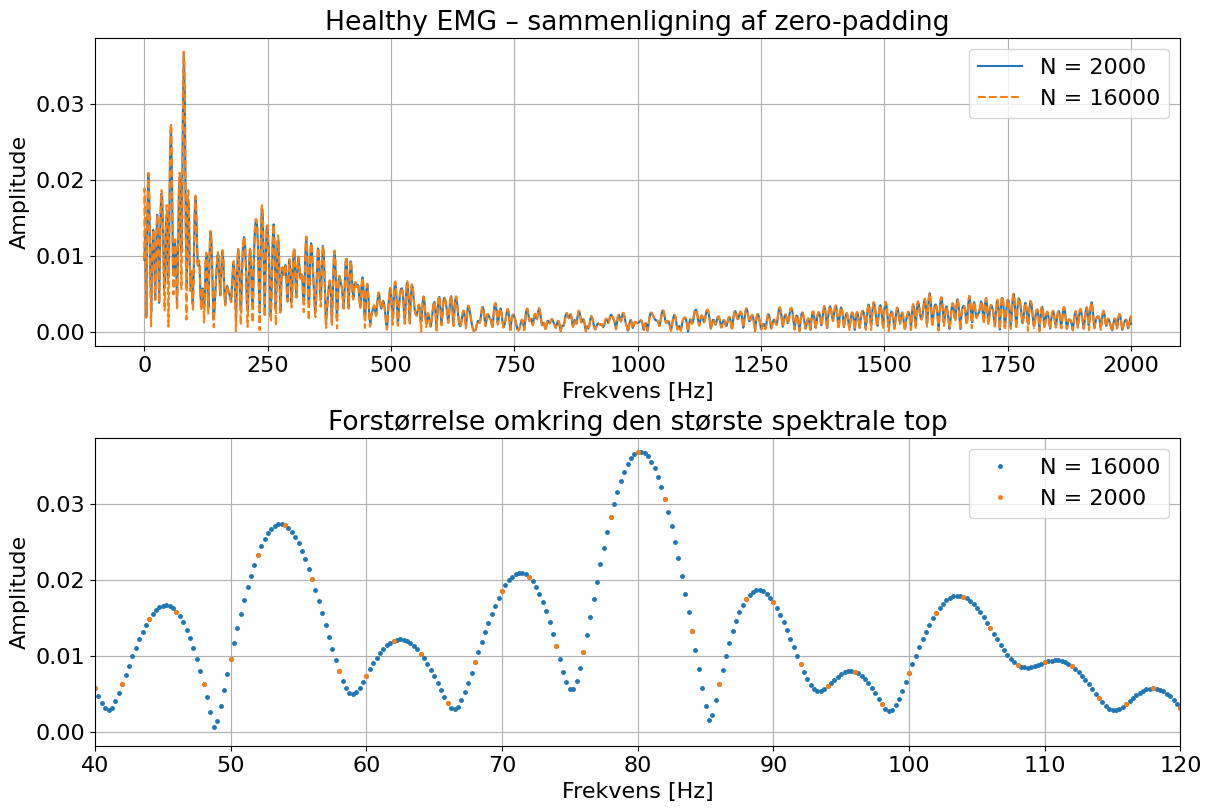

In [19]:

x = x_healthy

# Spektrum fra opgave 2
f_2000, A_2000 = amplitudespektrum(
    x, fs_healthy, N=2000
)

# Otte gange større FFT-længde
f_16000, A_16000 = amplitudespektrum(
    x, fs_healthy, N=16000
)

print(f"N = 2000:  Δf = {fs_healthy / 2000:.2f} Hz")
print(f"N = 16000: Δf = {fs_healthy / 16000:.2f} Hz")

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 8),
    constrained_layout=True
)

# Hele frekvensområdet
ax[0].plot(f_2000, A_2000, label="N = 2000")
ax[0].plot(f_16000, A_16000, linestyle="--", label="N = 16000")
ax[0].set_title("Healthy EMG – sammenligning af zero-padding")
ax[0].set_xlabel("Frekvens [Hz]")
ax[0].set_ylabel("Amplitude")
ax[0].legend()

# Forstørret område omkring den største top
ax[1].plot(f_16000, A_16000,".", markersize=5, label="N = 16000")
ax[1].plot(f_2000, A_2000, ".", markersize=5, label="N = 2000")
ax[1].set_xlim(40, 120)
ax[1].set_title("Forstørrelse omkring den største spektrale top")
ax[1].set_xlabel("Frekvens [Hz]")
ax[1].set_ylabel("Amplitude")
ax[1].legend()

plt.show()

Ved frekvenstransformationen med \(N=16000\) tilføjes der derfor
15370 nuller efter signalet.

Frekvensopløsningen ved \(N=2000\) var:

$$
\Delta f_{2000}
= \frac{4000}{2000}
= 2\,\mathrm{Hz}
$$

Ved \(N=16000\) bliver frekvensopløsningen:

$$
\Delta f_{16000}
= \frac{4000}{16000}
= 0{,}25\,\mathrm{Hz}
$$

De to spektre har samme overordnede form og omtrent samme
amplituder, fordi de er beregnet ud fra de samme målte samples.
Spektret med \(N=16000\) fremstår dog mere glat og detaljeret,

Zero-padding tilfører ikke ny information til signalet og forbedrer
ikke den egentlige evne til at adskille tætliggende frekvenser.
Det giver alene en tættere sampling af det eksisterende spektrum,
så det bliver lettere at aflæse og estimere placeringen af toppene.*

### 5. R-takker, puls og Heart Rate Variability

"Pulsen i et EKG-signal kan findes som gennemsnitsafstanden mellem kompleksernes R-takke. Vis hvordan, og diskuter hvor på frekvensspektret den samme
information må kunne findes. Man bør inddrage begrebet Heart Rate Variability."

Ved denne opgave kommer det til udtryk at vi begge er Datavidenskabs studerende og derfor ikke ved så meget indenfor sundhedsteknologi. Vi har brugt https://en.wikipedia.org/wiki/Heart_rate_variability og AI til at forstå 

R-takkerne findes som lokale maksima over en tærskel, med et mindste mellemrum på ca. 0.4 s, så samme QRS ikke giver to detektioner.

`signal.find_peaks`

**distance:** er den mindste tilladte afstand mellem to toppe, målt i samples. Her kræver vi mindst 0,4 sekunder mellem R-takkerne:
distance = 0.4 * 2000 = 800 samples

**prominence:** beskriver, hvor meget en top skal skille sig ud fra sine omgivelser.
prominence = 3 * np.std(ecg)

24650 EKG-målepunkter
Antal fundne R-takker: 13
Gennemsnitlig RR-afstand: 0.9575 s
Gennemsnitlig puls: 62.66 slag/min


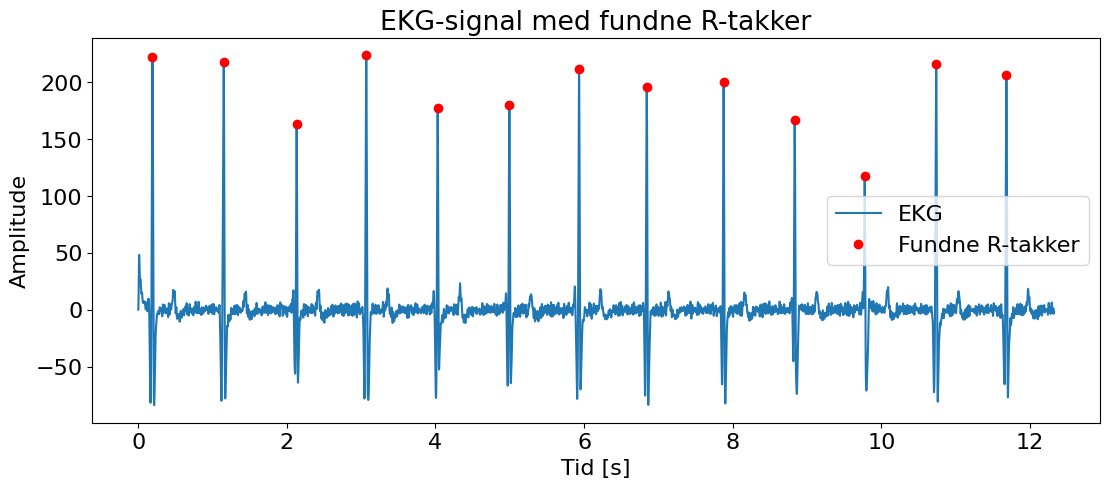

In [71]:
#Indlæs EKG-data
mat = loadmat("ECG_complex.mat")

#ravel() smaler EKG-målepunkterne i en endimensional array
ecg = mat["signal_EKG"].ravel()

#item() henter sample frekvensen et tal
fs_ecg = mat["f_sample"].item()

# Tidsakse til EKG-signalet
t_ecg = np.arange(len(ecg)) / fs_ecg

print(len(ecg), "EKG-målepunkter")

# Find R-takker
r_peaks, properties = signal.find_peaks(
    ecg,
    distance=int(0.4 * fs_ecg),
    prominence=3 * np.std(ecg)
)

r_times = r_peaks / fs_ecg

# Afstanden mellem R-takkerne
rr_intervals = np.diff(r_times)

# Gennemsnitlig RR-afstand og puls
mean_rr = np.mean(rr_intervals)
pulse_bpm = 60 / mean_rr

print(f"Antal fundne R-takker: {len(r_peaks)}")
print(f"Gennemsnitlig RR-afstand: {mean_rr:.4f} s")
print(f"Gennemsnitlig puls: {pulse_bpm:.2f} slag/min")

plt.figure(figsize=(13, 5))

plt.plot(t_ecg, ecg, label="EKG")
plt.plot(
    r_times,
    ecg[r_peaks],
    "ro",
    label="Fundne R-takker"
)

plt.xlabel("Tid [s]")
plt.ylabel("Amplitude")
plt.title("EKG-signal med fundne R-takker")
plt.legend()
plt.grid()
plt.show()

gennemsnits pulsen findes til 62.66 slag/min, man vil kunne finde samme infomation i plottet, ved at tælle antal R-takker i et 12 sekunders segment og gange med 5, 13*5 = 65 slag/min hvilket er rimelig tæt på

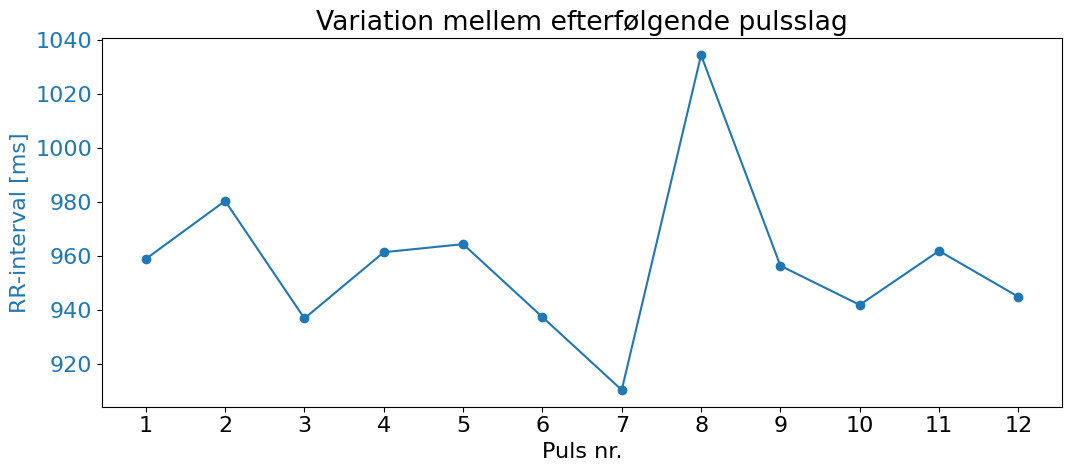

SDNN: 28.83 ms


In [50]:
# Puls nr. 1 viser forskellen mellem pulsslag 1 og 2
puls_nr = np.arange(1, len(rr_intervals) + 1)

# Metrik 1: tidsafstand mellem efterfølgende R-takker
rr_ms = rr_intervals * 1000

# Metrik 2: absolut højdeforskel mellem efterfølgende R-takker
r_heights = ecg[r_peaks]
height_difference = np.abs(np.diff(r_heights))

fig, ax1 = plt.subplots(figsize=(11, 5))

# Venstre y-akse: RR-interval
line1 = ax1.plot(
    puls_nr,
    rr_ms,
    "o-",
    color="tab:blue",
    label="RR-interval"
)

ax1.set_xlabel("Puls nr.")
ax1.set_ylabel("RR-interval [ms]", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.set_xticks(puls_nr)
ax1.grid()

plt.title("Variation mellem efterfølgende pulsslag")
plt.tight_layout()
plt.show()

sdnn = np.std(rr_intervals) * 1000
print(f"SDNN: {sdnn:.2f} ms")

SDNN beskriver den samlede variation i RR-intervallerne.


(0.0, 5.0)

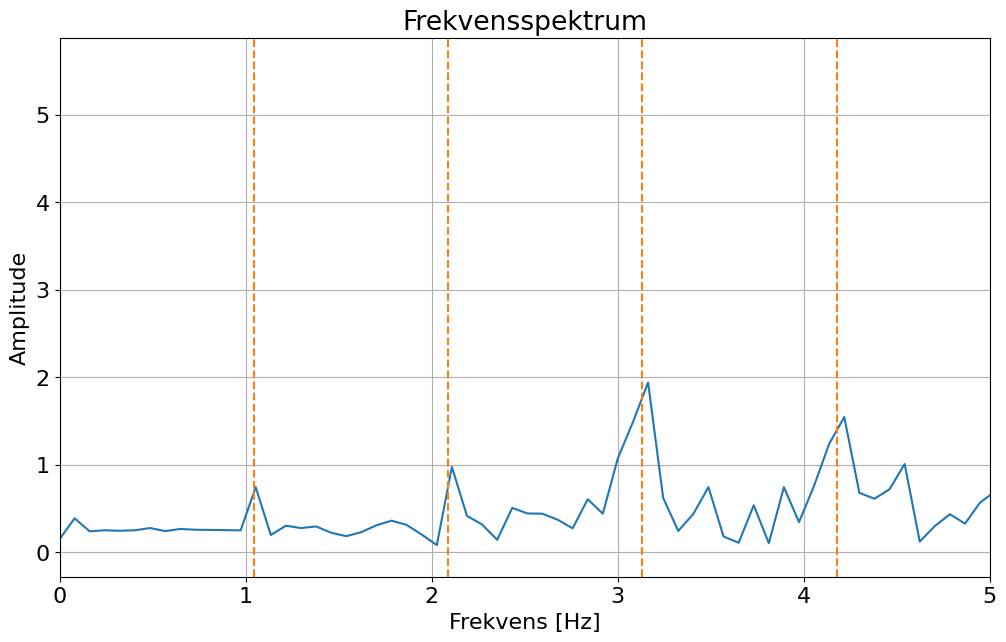

In [81]:
f_ecg, A_ecg = amplitudespektrum(ecg, fs_ecg, N=24650)

fig, ax = plt.subplots(
    figsize=(12, 7),
)

ax.plot(f_ecg, A_ecg)
ax.set_title("Frekvensspektrum")
ax.set_ylabel("Amplitude")
ax.set_xlabel("Frekvens [Hz]")
ax.axvline(1/mean_rr, color="tab:orange", linestyle="--", label="0.5 Hz")
ax.axvline(2*1/mean_rr, color="tab:orange", linestyle="--", label="0.5 Hz")
ax.axvline(3*1/mean_rr, color="tab:orange", linestyle="--", label="0.5 Hz")
ax.axvline(4*1/mean_rr, color="tab:orange", linestyle="--", label="0.5 Hz")
ax.set_xlim(0, 5)

Den gennemsnitlige RR-afstand blev bestemt til
\(0{,}9575\,\mathrm{s}\), hvilket giver en gennemsnitlig puls på:

$$
\mathrm{puls}
=
\frac{60}{0{,}9575}
\approx 62{,}66\ \mathrm{slag/min}
$$

Den tilsvarende gentagelsesfrekvens er:

$$
f_{\mathrm{puls}}
=
\frac{1}{0{,}9575}
\approx 1{,}044\,\mathrm{Hz}
$$

På EKG-spektret findes en frekvenskomponent omkring
$1{,}04\,\mathrm{Hz}$. Det er den samme pulsinformation, som blev
fundet ud fra R-takkerne. I det zero-paddede spektrum ligger den
lokale top omkring $1{,}045\,\mathrm{Hz} $.

Der ses også frekvenskomponenter ved multipla af pulsfrekvensen.
Disse harmoniske opstår, fordi QRS-komplekset har en skarp og
ikke-sinusformet form. Grundfrekvensen ved cirka $1{,}04\,\mathrm{Hz}$
behøver derfor ikke at være spektrets største top.

RR-intervallerne er ikke helt ens, hvilket betegnes Heart Rate
Variability. Denne variation gør, at frekvensindholdet omkring
pulsfrekvensen og dens harmoniske bliver mere spredt.

### R-takker, puls og Heart Rate Variability

R-takkerne blev fundet som tydelige lokale maksima i EKG-signalet.
Der blev fundet 13 R-takker og dermed 12 RR-intervaller. Den
gennemsnitlige afstand mellem R-takkerne blev bestemt til:

$$
\overline{RR}=0{,}9575\,\mathrm{s}
$$

Den gennemsnitlige puls bliver derfor:

$$
\mathrm{puls}
=
\frac{60}{\overline{RR}}
=
\frac{60}{0{,}9575}
\approx62{,}66\ \mathrm{slag/min}
$$

Denne puls svarer til en grundfrekvens på:

$$
f_0
=
\frac{1}{\overline{RR}}
\approx1{,}044\,\mathrm{Hz}
$$

I det zero-paddede frekvensspektrum findes en lokal top omkring
\(1{,}045\,\mathrm{Hz}\). Dette stemmer godt overens med
grundfrekvensen beregnet ud fra RR-intervallerne. Den samme
information om pulsen kan dermed findes både i tidsdomænet og
frekvensdomænet.

EKG-signalets største spektrale top behøver ikke at ligge ved
grundfrekvensen. Et EKG-kompleks består af P-, Q-, R-, S- og
T-takker og er derfor ikke sinusformet. Især det skarpe
QRS-kompleks bidrager med frekvensindhold ved højere frekvenser.
Der opstår derfor harmoniske komponenter omkring:

$$
2f_0,\ 3f_0,\ 4f_0,\ldots
$$

Komponenten ved eksempelvis \(2f_0\) betyder ikke, at hjertet slår
dobbelt så hurtigt. Den er en harmonisk komponent, som er nødvendig
for at beskrive formen af det gentagne EKG-kompleks.

RR-intervallerne varierer mellem cirka \(910{,}5\,\mathrm{ms}\) og
\(1034{,}5\,\mathrm{ms}\). Denne variation i tiden mellem
hjerteslagene kaldes Heart Rate Variability, HRV. Der blev beregnet:

$$
\mathrm{SDNN}=30{,}11\,\mathrm{ms}
$$

$$
\mathrm{RMSSD}=49{,}34\,\mathrm{ms}
$$

SDNN beskriver den samlede variation i RR-intervallerne, mens RMSSD
beskriver ændringen fra ét RR-interval til det næste. HRV medfører,
at hjerteslagene ikke er perfekt periodiske. Derfor bliver
frekvenskomponenterne omkring grundfrekvensen og dens harmoniske
mere spredte.

EKG-signalet har en samplefrekvens på \(2000\,\mathrm{Hz}\), hvilket
giver en Nyquistfrekvens på:

$$
f_\mathrm{Nyquist}
=
\frac{f_s}{2}
=
1000\,\mathrm{Hz}
$$

Nyquistfrekvensen bestemmer den højeste frekvens, som kan vises
korrekt, men den skaber ikke de harmoniske komponenter. De opstår
på grund af EKG-kompleksets ikke-sinusformede og skarpe form.

Optagelsen varer kun cirka 12,3 sekunder og indeholder 12
RR-intervaller. HRV-beregningerne viser derfor princippet, men
optagelsen er for kort til en pålidelig klinisk vurdering af HRV.

### 6. STFT og frekvensindhold i hvert QRS-kompleks


"Lav STFT på EKG-signalet og vis frekvensindholdet for hvert QRS-kompleks."

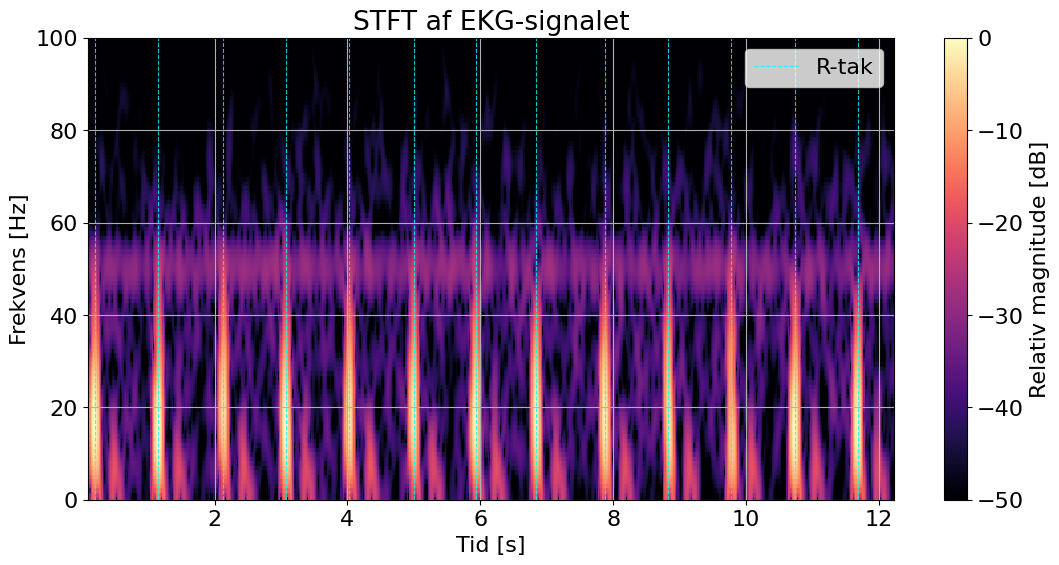

In [ ]:
# Fjern signalets middelværdi
ecg_centered = ecg - np.mean(ecg)

# STFT-parametre
window_length = int(0.2 * fs_ecg)     # 200 ms
overlap = int(0.9 * window_length)    # 90 % overlap
N_fft = 2048 # 24650

f_stft, t_stft, Z_stft = signal.stft(
    ecg_centered,
    fs=fs_ecg,
    window="hann",
    nperseg=window_length,
    noverlap=overlap,
    nfft=N_fft,
    boundary=None,
    padded=False
)

# Relativ magnitude i dB
magnitude = np.abs(Z_stft)

magnitude_db = 20 * np.log10(
    magnitude / np.max(magnitude) + 1e-12
)

# Vis kun det relevante frekvensområde
frequency_mask = f_stft <= 100

fig, ax = plt.subplots(figsize=(13, 6))

image = ax.pcolormesh(
    t_stft,
    f_stft[frequency_mask],
    magnitude_db[frequency_mask],
    shading="auto",
    cmap="magma",
    vmin=-50,
    vmax=0
)

# Markér tidspunktet for hver R-tak
for i, r_time in enumerate(r_times):
    ax.axvline(
        r_time,
        color="cyan",
        linestyle="--",
        linewidth=0.8,
        alpha=0.8,
        label="R-tak" if i == 0 else None
    )

ax.set_xlabel("Tid [s]")
ax.set_ylabel("Frekvens [Hz]")
ax.set_title("STFT af EKG-signalet")
ax.set_ylim(0, 100)
ax.legend()

fig.colorbar(
    image,
    ax=ax,
    label="Relativ magnitude [dB]"
)

plt.show()

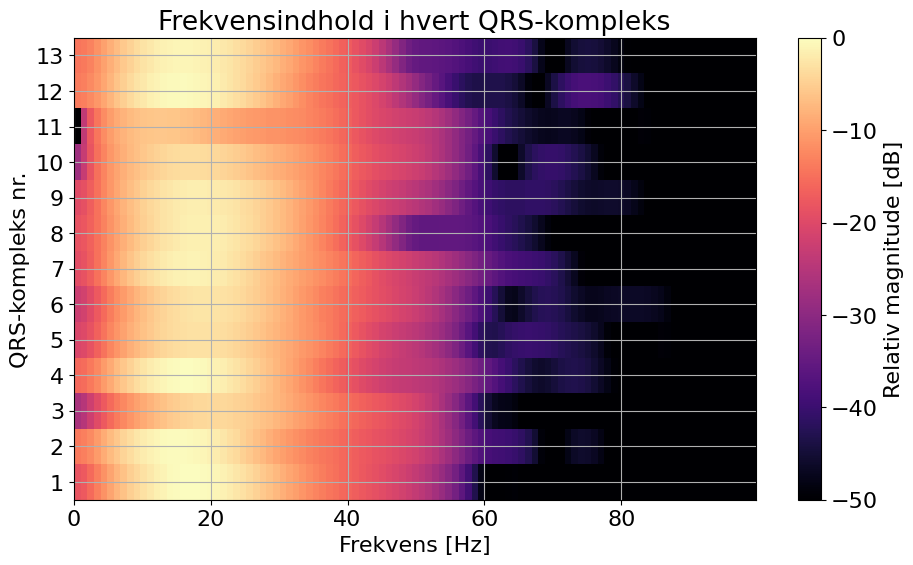

In [84]:
# Find STFT-vinduet nærmest hver R-tak
qrs_columns = np.array([
    np.argmin(np.abs(t_stft - r_time))
    for r_time in r_times
])

# Frekvensindhold ved hvert QRS-kompleks
qrs_spectra_db = magnitude_db[
    frequency_mask
][:, qrs_columns].T

plt.figure(figsize=(11, 6))

plt.imshow(
    qrs_spectra_db,
    aspect="auto",
    origin="lower",
    extent=[
        f_stft[frequency_mask][0],
        f_stft[frequency_mask][-1],
        0.5,
        len(r_peaks) + 0.5
    ],
    cmap="magma",
    vmin=-50,
    vmax=0
)

plt.xlabel("Frekvens [Hz]")
plt.ylabel("QRS-kompleks nr.")
plt.title("Frekvensindhold i hvert QRS-kompleks")
plt.yticks(np.arange(1, len(r_peaks) + 1))
plt.colorbar(label="Relativ magnitude [dB]")
plt.show()

### STFT af EKG-signalet

EKG-signalet blev analyseret med en Short-Time Fourier Transform.
Der blev anvendt et Hann-vindue med en længde på 200 ms og 90 %
overlap. Et kort vindue er valgt, fordi QRS-komplekserne er
kortvarige, og det skal være muligt at adskille dem i tid.

I spektrogrammet ses hvert QRS-kompleks som et lyst, næsten lodret
område omkring tidspunktet for den tilhørende R-tak. De lodrette
områder opstår, fordi QRS-komplekset indeholder hurtige og skarpe
ændringer og derfor har frekvensindhold over et bredt
frekvensområde. Mellem QRS-komplekserne er den spektrale amplitude
generelt mindre.

QRS-komplekserne har overordnet et lignende frekvensindhold, fordi
deres former minder om hinanden. Forskelle i farveintensiteten
skyldes blandt andet variationer i QRS-kompleksernes amplitude og
form.

Der ses desuden en komponent omkring 50 Hz, som er til stede over
næsten hele optagelsen. Da denne komponent ikke kun optræder ved
QRS-komplekserne, skyldes den sandsynligvis elektrisk netstøj og
ikke selve hjerteaktiviteten.

STFT'en viser dermed både tidspunktet og frekvensindholdet for
hvert QRS-kompleks. Dette kan ikke ses i én almindelig Fourier-
transformation, fordi den kun viser signalets samlede
frekvensindhold og ikke, hvornår de enkelte frekvenskomponenter
optræder.